# Generative AI Applications — CVE-Style Vulnerability Description Generation with a Fine-Tuned Transformer
**Goal (Task 1):** Fine-tune a decoder-only Transformer on English CVE descriptions to study whether it learns the wording and structure of vulnerability notices. Generated continuations are fictional examples for classroom analysis.

- **Approach:** Transformer-based text generation (Hugging Face `transformers` + PyTorch)
- **Author:** Vu Tran · Date: November 11, 2026

## 1. Environment Check

In [1]:
import os
import subprocess
import json
import math
import random
import sys
from pathlib import Path
import seaborn as sns

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import display
from torch.utils.data import DataLoader
from transformers import AutoModelForCausalLM, AutoTokenizer

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__,
      'Transformers', transformers.__version__, 'Device', device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

Python 3.14.4 PyTorch 2.15.0+cu132 Transformers 5.22.2 Device cuda
NVIDIA RTX A3000 12GB Laptop GPU


## 2. Data Source and Provenance
| Field | Value |
|---|---|
| Upstream | [CVEProject/cvelistV5](https://github.com/CVEProject/cvelistV5) |
| Scope | CVE-2021-* identifiers under `cves/2021`, with publication dates retained separately |
| Snapshot | `3cb4c6bfb5fbd74de5b87f5158f97c0c56da8f88` |
| Raw directory | `../_raw/cvelistV5/cves/2021` |
| Derived dataset | `data/cve_2021_descriptions.csv` |

The corpus uses the English descriptions published by CVE Numbering Authorities (CNAs). Their notices provide examples of advisory language across vendors and products.

### Rebuild the dataset
```bash
git clone --filter=blob:none --sparse https://github.com/CVEProject/cvelistV5.git ../_raw/cvelistV5
git -C ../_raw/cvelistV5 checkout --detach 3cb4c6bfb5fbd74de5b87f5158f97c0c56da8f88
git -C ../_raw/cvelistV5 sparse-checkout set cves/2021
git -C ../_raw/cvelistV5 rev-parse HEAD
```

## 3. Load and Inspect the Data

In [3]:
repo = Path('../_raw/cvelistV5')
raw = repo / 'cves' / '2021'
members = sorted(raw.rglob('CVE-2021-*.json'))
if not members:
    raise FileNotFoundError(f'No CVE-2021 JSON files under {raw.resolve()}')
commit = subprocess.check_output(
    ['git', '-C', str(repo), 'log', '-1', '--format=%H'], text=True
).strip()
print('CVE List V5 snapshot:', commit)
rows = []
for path in members:
    record = json.loads(path.read_text(encoding='utf-8'))
    metadata = record.get('cveMetadata', {})
    if metadata.get('state') != 'PUBLISHED':
        continue
    cna = record.get('containers', {}).get('cna', {})
    description = next(
        (item['value'] for item in cna.get('descriptions', [])
         if item.get('lang', '').lower().startswith('en')
         and item.get('value', '').strip()), ''
    )
    if not description:
        continue
    affected = cna.get('affected', [])
    cwes = sorted({entry['cweId']
                   for group in cna.get('problemTypes', [])
                   for entry in group.get('descriptions', [])
                   if entry.get('cweId')})
    rows.append(dict(cve_id=metadata['cveId'],
                     published=metadata.get('datePublished'),
                     cna=metadata.get('assignerShortName') or
                         cna.get('providerMetadata', {}).get('shortName', 'Unknown'),
                     cwes=cwes,
                     vendors=sorted({a['vendor'] for a in affected if a.get('vendor')}),
                     products=sorted({a['product'] for a in affected if a.get('product')}),
                     description=description))
df = pd.DataFrame(rows)
assert not df.empty, 'No published records with English descriptions were found.'
print(f'{len(members)} JSON files, {len(df)} eligible records')
csv_path = Path('data/cve_2021_descriptions.csv')
csv_path.parent.mkdir(exist_ok=True)
df.assign(snapshot_commit=commit).to_csv(csv_path, index=False)
print('Wrote', csv_path)
print('Unique CNAs:', df.cna.nunique())

CVE List V5 snapshot: 3cb4c6bfb5fbd74de5b87f5158f97c0c56da8f88
23494 JSON files, 22613 eligible records
Wrote data/cve_2021_descriptions.csv
Unique CNAs: 178


In [4]:
df.info()
display(df.drop(columns='description').head())
for row in df.drop_duplicates('cna').head(4).itertuples():
    print(f'{row.cve_id} ({row.cna}): {row.description}\n')

<class 'pandas.DataFrame'>
RangeIndex: 22613 entries, 0 to 22612
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   cve_id       22613 non-null  str   
 1   published    22613 non-null  str   
 2   cna          22613 non-null  str   
 3   cwes         22613 non-null  object
 4   vendors      22613 non-null  object
 5   products     22613 non-null  object
 6   description  22613 non-null  str   
dtypes: object(3), str(4)
memory usage: 1.2+ MB


,cve_id,published,cna,cwes,vendors,products
0,CVE-2021-0001,2021-06-09T19:01:55.000Z,intel,[],[n/a],[Intel(R) IPP]
1,CVE-2021-0002,2021-08-11T12:48:10.000Z,intel,[],[n/a],[Intel(R) Ethernet Controllers 800 series Linu...
2,CVE-2021-0003,2021-08-11T12:48:20.000Z,intel,[],[n/a],[Intel(R) Ethernet Controllers 800 series Linu...
3,CVE-2021-0004,2021-08-11T12:47:04.000Z,intel,[],[n/a],[Intel(R) Ethernet Adapters 800 Series Control...
4,CVE-2021-0005,2021-08-11T12:47:11.000Z,intel,[],[n/a],[Intel(R) Ethernet Adapters 800 Series Control...


CVE-2021-0001 (intel): Observable timing discrepancy in Intel(R) IPP before version 2020 update 1 may allow authorized user to potentially enable information disclosure via local access.

CVE-2021-0202 (juniper): On Juniper Networks MX Series and EX9200 Series platforms with Trio-based MPC (Modular Port Concentrator) where Integrated Routing and Bridging (IRB) interface is configured and it is mapped to a VPLS instance or a Bridge-Domain, certain network events at Customer Edge (CE) device may cause memory leak in the MPC which can cause an out of memory and MPC restarts. When this issue occurs, there will be temporary traffic interruption until the MPC is restored. An administrator can use the following CLI command to monitor the status of memory usage level of the MPC: user@device> show system resource-monitor fpc FPC Resource Usage Summary Free Heap Mem Watermark : 20 % Free NH Mem Watermark : 20 % Free Filter Mem Watermark : 20 % * - Watermark reached Slot # % Heap Free RTT Average

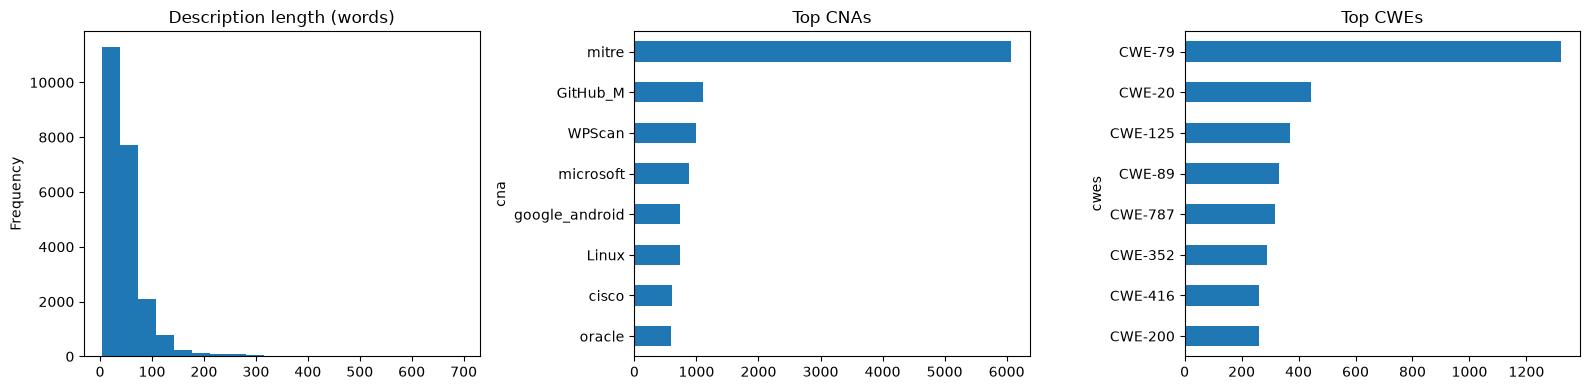

count    22613.000000
mean        49.257507
std         45.124405
min          4.000000
25%         25.000000
50%         39.000000
75%         57.000000
max        696.000000
Name: description, dtype: float64
Exact duplicate rows: 1466


description
in the linux kernel, the following                      731
this vulnerability allows remote attackers to           305
a vulnerability has been identified in                  280
certain netgear devices are affected by                 205
an issue was discovered in the                          192
multiple vulnerabilities in the web-based management    179
tensorflow is an end-to-end open source                 166
vulnerability in the mysql server product               149
Name: count, dtype: int64

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
words = df.description.str.split().str.len()
words.plot.hist(ax=axes[0], bins=20, title='Description length (words)')
df.cna.value_counts().head(8).sort_values().plot.barh(ax=axes[1], title='Top CNAs')
cwe_counts = df.cwes.explode().value_counts().head(8)
if not cwe_counts.empty:
    cwe_counts.sort_values().plot.barh(ax=axes[2], title='Top CWEs')
fig.tight_layout()
plt.show()
print(words.describe())
print('Exact duplicate rows:', df.description.duplicated().sum())
prefixes = df.description.str.lower().str.split().str[:6].str.join(' ')
display(prefixes.value_counts().loc[lambda counts: counts > 1].head(8))

In [6]:
linux = df[df.description.str.startswith('In the Linux kernel, the following')]
print('Linux-kernel-opening records:', len(linux))
print(linux.published.str[:4].value_counts().sort_index())

Linux-kernel-opening records: 731
published
2024    694
2025     37
Name: count, dtype: int64


The corpus contained 22,613 eligible English descriptions from 178 CNAs. The median description had 39 words, the 75th percentile was 57, and the longest had 696. There were 1,466 exact duplicate descriptions beyond their first occurrence. The opening “In the Linux kernel, the following” appeared 731 times, followed by “This vulnerability allows remote attackers to” (305) and “A vulnerability has been identified in” (280). Of the 731 Linux-kernel-opening records, 694 were published in 2024 and 37 in 2025, illustrating how the identifier year and publication year can differ. Grouping by the first six words keeps identical openings together, though paraphrased templates can still cross the split.

## 4. Preprocessing
**Design choices:** I collapsed extra whitespace but kept the original punctuation, so the model learns real advisory formatting. Descriptions shorter than 8 words and exact duplicates were removed. To limit leakage from templated text, I split train and validation by each record's first six words, so records that open the same way always land in the same split. I held out about 20% of records this way: 16,618 training and 4,202 validation records (20.2%) across 2,569 opening groups. Each record is one training sequence, capped at 256 tokens. An end-of-text token is added only when the full record fits, and padding is masked out of the loss.

In [7]:
clean = df.assign(text=df.description.str.split().str.join(' '))
clean = clean.loc[clean.text.str.split().str.len() >= 8].drop_duplicates('text')
openings = clean.text.str.lower().str.split().str[:6].str.join(' ')
groups = sorted(openings.unique())
random.Random(SEED).shuffle(groups)
validation_openings = set()
validation_count = 0
for group in groups[:-1]:
    validation_openings.add(group)
    validation_count += int(openings.eq(group).sum())
    if validation_count >= 0.2 * len(clean):
        break
val_mask = openings.isin(validation_openings)
train_texts = clean.loc[~val_mask, 'text'].tolist()
val_texts = clean.loc[val_mask, 'text'].tolist()
assert train_texts and val_texts, 'Both splits need at least one record.'
print(f'Train: {len(train_texts)}; validation: {len(val_texts)}')
print('Validation opening groups:', len(validation_openings))

Train: 16618; validation: 4202
Validation opening groups: 2569


In [8]:
MODEL_ID = 'distilbert/distilgpt2'
MODEL_REVISION = '2290a62682d06624634c1f46a6ad5be0f47f38aa'
CHECKPOINT = os.environ.get('DISTILGPT2_DIR', MODEL_ID)
model_source = {'revision': MODEL_REVISION} if CHECKPOINT == MODEL_ID else {}
MAX_TOKENS = 256
BATCH_SIZE = 16
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT, **model_source)
tokenizer.pad_token = tokenizer.eos_token

def encode(text):
    ids = tokenizer.encode(text, add_special_tokens=False)
    return (ids + [tokenizer.eos_token_id])[:MAX_TOKENS]

def collate(sequences):
    batch = tokenizer.pad({'input_ids': sequences}, return_tensors='pt')
    batch['labels'] = batch['input_ids'].masked_fill(batch['attention_mask'] == 0, -100)
    return batch

train_sequences = [encode(text) for text in train_texts]
val_sequences = [encode(text) for text in val_texts]
print('Training tokens:', sum(map(len, train_sequences)))
print('Validation tokens:', sum(map(len, val_sequences)))
train_loader = DataLoader(train_sequences, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), collate_fn=collate)
val_loader = DataLoader(val_sequences, batch_size=BATCH_SIZE, collate_fn=collate)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1382 > 1024). Running this sequence through the model will result in indexing errors


Training tokens: 1265753
Validation tokens: 326486


## 5. Model Architecture
**Design choices:** DistilGPT2 is a pretrained decoder-only Transformer with 6 layers, 12 attention heads, and about 82 million parameters. Token and position embeddings feed causal self-attention and feed-forward blocks, followed by a projection onto the vocabulary. The causal mask means each token can only attend to earlier tokens, which matches next-token text generation. I chose the distilled model because it is small enough to fine-tune all parameters on a 12 GB laptop GPU.

In [9]:
model = AutoModelForCausalLM.from_pretrained(CHECKPOINT, **model_source).to(device)
print(model.config)
print(model)
print('Total parameters:', sum(p.numel() for p in model.parameters()))
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

GPT2Config {
  "_num_labels": 1,
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "id2label": {
    "0": "LABEL_0"
  },
  "initializer_range": 0.02,
  "label2id": {
    "LABEL_0": 0
  },
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 6,
  "n_positions": 1024,
  "pad_token_id": null,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transform

## 6. Baseline Generation (Before Fine-Tuning)

In [10]:
# Select distinct human-authored openings from held-out records.
# Exclude any four-word prompt that also opens a training record.
def opening(text):
    return ' '.join(text.split()[:4])

train_openings = {opening(text).casefold() for text in train_texts}
prompts = []
seen = set(train_openings)
for text in random.Random(SEED).sample(val_texts, len(val_texts)):
    prompt = opening(text)
    if prompt.casefold() not in seen:
        prompts.append(prompt)
        seen.add(prompt.casefold())
    if len(prompts) == 3:
        break
assert len(prompts) == 3, 'Expected three distinct held-out source openings.'
settings = [(0.7, 0.90), (1.0, 0.95)]

@torch.inference_mode()
def sample(stage):
    model.eval()
    results = []
    for prompt_index, prompt in enumerate(prompts, start=1):
        inputs = tokenizer(prompt, return_tensors='pt').to(device)
        for setting_index, (temperature, top_p) in enumerate(settings, start=1):
            for repeat in range(1, 3):
                seed = SEED + 10 * prompt_index + repeat
                torch.manual_seed(seed)
                ids = model.generate(**inputs, do_sample=True, temperature=temperature,
                                     top_p=top_p, top_k=0, max_new_tokens=48,
                                     pad_token_id=tokenizer.pad_token_id)
                continuation = ids[0, inputs.input_ids.shape[1]:]
                results.append(dict(sample_id=f'{stage}-{prompt_index}-{setting_index}-{repeat}',
                                    prompt=prompt, temperature=temperature, top_p=top_p, seed=seed,
                                    output=tokenizer.decode(continuation, skip_special_tokens=True)))
    return pd.DataFrame(results)

baseline = sample('baseline')
with pd.option_context('display.max_colwidth', None):
    display(baseline)

,sample_id,prompt,temperature,top_p,seed,output
0,baseline-1-1-1,A race condition was,0.7,0.90,53,not reported.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
1,baseline-1-1-2,A race condition was,0.7,0.90,54,not determined.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
2,baseline-1-2-1,A race condition was,1.0,0.95,53,"indicated by the new litter list of ‒Amion‬s which are well known to be really ‹Acceptable‬s. After receiving 10 of their ‒Amion‬s, Amion with two left left"
3,baseline-1-2-2,A race condition was,1.0,0.95,54,"removed during the 6-1 victory over the Crook City Boys on September 6, 2015. (Photo: AJ Lee/EPA)\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n"
4,baseline-2-1-1,SAP 3D Visual Enterprise,0.7,0.90,63,: A Visual Studio 2010 Build.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
5,baseline-2-1-2,SAP 3D Visual Enterprise,0.7,0.90,64,for Windows 7\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
6,baseline-2-2-1,SAP 3D Visual Enterprise,1.0,0.95,63,: One of the most useful foundational services to developers. You'll even find an application that is not included on the market. One of the most useful foundational services to developers. You'll even find an application that is not included on the market
7,baseline-2-2-2,SAP 3D Visual Enterprise,1.0,0.95,64,"Black Hole Updated Post-Only Visual Enterprise Black Hole Detector\n\n[95] Repository Links to Rebuilding Digital Abundance on EDSI VPNs\n[96] Bank video - ""Reports of a Breakdown of an"
8,baseline-3-1-1,Improper MDM policy management,0.7,0.90,73,software is a new and innovative approach to managing your data in a way that is easy to implement and even more intuitive.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
9,baseline-3-1-2,Improper MDM policy management,0.7,0.90,74,.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n


## 7. Training
**Design choices:** Fine-tune all parameters for three epochs with AdamW at a learning rate of 5e-5, batch size 16, and gradient norms clipped to 1.0. Hugging Face shifts the labels internally to compute causal cross-entropy. Each batch's loss is weighted by its number of predicted non-padding tokens, so the epoch loss is a true per-token average. Training uses full 32-bit precision for this run.

In [11]:
EPOCHS = 3
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss = 0.0
    total_tokens = 0
    with torch.set_grad_enabled(training):
        for batch in loader:
            batch = {key: value.to(device) for key, value in batch.items()}
            if training:
                optimizer.zero_grad(set_to_none=True)
            loss = model(**batch, use_cache=False).loss
            if not torch.isfinite(loss):
                raise RuntimeError('Encountered non-finite loss.')
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            tokens = batch['labels'][:, 1:].ne(-100).sum().item()
            total_loss += loss.item() * tokens
            total_tokens += tokens
    return total_loss / total_tokens

In [12]:
initial_val = run_epoch(val_loader)
history = []
for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader)
    history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss))
    print(f'Epoch {epoch}: train={train_loss:.4f}, validation={val_loss:.4f}')

checkpoint_dir = Path('checkpoints/distilgpt2-cve')
model.save_pretrained(checkpoint_dir)
tokenizer.save_pretrained(checkpoint_dir)

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch 1: train=3.0225, validation=2.7214
Epoch 2: train=2.5279, validation=2.5802
Epoch 3: train=2.3308, validation=2.5137


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('checkpoints/distilgpt2-cve/tokenizer_config.json',
 'checkpoints/distilgpt2-cve/tokenizer.json')

## 8. Training Diagnostics

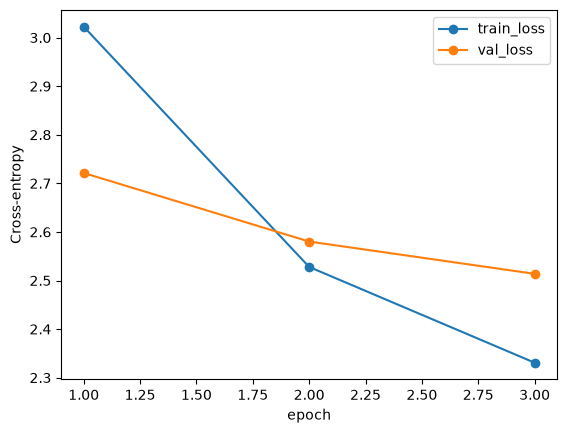

Validation perplexity: 58.69 → 12.35


In [13]:
losses = pd.DataFrame(history)
losses.plot(x='epoch', y=['train_loss', 'val_loss'], marker='o', ylabel='Cross-entropy')
plt.show()
print(f'Validation perplexity: {math.exp(initial_val):.2f} → {math.exp(history[-1]["val_loss"]):.2f}')

Training loss fell from 3.0225 to 2.5279 to 2.3308. Validation loss fell from 2.7214 to 2.5802 to 2.5137, with successive improvements of 0.1412 and 0.0665. Validation perplexity fell from 58.69 for the pretrained checkpoint to 12.35 after fine-tuning. The validation-minus-training gap grew from 0.0523 in epoch 2 to 0.1829 in epoch 3. This widening gap and the smaller validation gain suggest diminishing returns and possible emerging overfitting. Validation still improved at epoch 3, so the run does not establish which epoch would minimize validation loss.

## 9. Generate Samples
Both checkpoints use the same three held-out source excerpts, random seeds, and two temperature/top-p settings. Each continuation has a maximum of 48 new tokens.

In [14]:
fine_tuned = sample('fine-tuned')
samples = pd.concat([baseline, fine_tuned], ignore_index=True)
with pd.option_context('display.max_colwidth', None):
    display(samples)

,sample_id,prompt,temperature,top_p,seed,output
0,baseline-1-1-1,A race condition was,0.7,0.90,53,not reported.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
1,baseline-1-1-2,A race condition was,0.7,0.90,54,not determined.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
2,baseline-1-2-1,A race condition was,1.0,0.95,53,"indicated by the new litter list of ‒Amion‬s which are well known to be really ‹Acceptable‬s. After receiving 10 of their ‒Amion‬s, Amion with two left left"
3,baseline-1-2-2,A race condition was,1.0,0.95,54,"removed during the 6-1 victory over the Crook City Boys on September 6, 2015. (Photo: AJ Lee/EPA)\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n"
4,baseline-2-1-1,SAP 3D Visual Enterprise,0.7,0.90,63,: A Visual Studio 2010 Build.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
5,baseline-2-1-2,SAP 3D Visual Enterprise,0.7,0.90,64,for Windows 7\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
6,baseline-2-2-1,SAP 3D Visual Enterprise,1.0,0.95,63,: One of the most useful foundational services to developers. You'll even find an application that is not included on the market. One of the most useful foundational services to developers. You'll even find an application that is not included on the market
7,baseline-2-2-2,SAP 3D Visual Enterprise,1.0,0.95,64,"Black Hole Updated Post-Only Visual Enterprise Black Hole Detector\n\n[95] Repository Links to Rebuilding Digital Abundance on EDSI VPNs\n[96] Bank video - ""Reports of a Breakdown of an"
8,baseline-3-1-1,Improper MDM policy management,0.7,0.90,73,software is a new and innovative approach to managing your data in a way that is easy to implement and even more intuitive.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n
9,baseline-3-1-2,Improper MDM policy management,0.7,0.90,74,.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n


## 10. Quantitative Checks (optional)

In [15]:
def diversity(outputs):
    tokens = [text.lower().split() for text in outputs]
    unigrams = [word for sequence in tokens for word in sequence]
    bigrams = [pair for sequence in tokens for pair in zip(sequence, sequence[1:])]
    return pd.Series({
        'mean_words': np.mean([len(sequence) for sequence in tokens]),
        'distinct_1': len(set(unigrams)) / max(1, len(unigrams)),
        'distinct_2': len(set(bigrams)) / max(1, len(bigrams)),
    })

by_stage = samples.assign(stage=['baseline'] * len(baseline) +
                              ['fine-tuned'] * len(fine_tuned))
display(by_stage.groupby(['stage', 'temperature', 'top_p'])['output'].apply(diversity).unstack())
def fivegrams(text):
    words = text.casefold().split()
    return set(zip(*(words[offset:] for offset in range(5))))

train_phrases = set()
for text in train_texts:
    train_phrases.update(fivegrams(text))

def training_overlap(text):
    phrases = fivegrams(text)
    return len(phrases & train_phrases) / len(phrases) if phrases else float('nan')

samples['training_5gram_overlap'] = samples.output.map(training_overlap)
display(samples[['sample_id', 'training_5gram_overlap']])

mean_words  distinct_1  distinct_2
stage      temperature top_p                                    
baseline   0.7         0.90     6.166667    0.837838    1.000000
           1.0         0.95    27.833333    0.658683    0.838509
fine-tuned 0.7         0.90    26.500000    0.610063    0.888889
           1.0         0.95    25.000000    0.713333    0.930556

,sample_id,training_5gram_overlap
0,baseline-1-1-1,NaN
1,baseline-1-1-2,NaN
2,baseline-1-2-1,0.000000
3,baseline-1-2-2,0.000000
4,baseline-2-1-1,0.000000
5,baseline-2-1-2,NaN
6,baseline-2-2-1,0.000000
7,baseline-2-2-2,0.000000
8,baseline-3-1-1,0.052632
9,baseline-3-1-2,NaN


## 11. Qualitative Evaluation
Under matched settings, baseline-1-2-2 drifted into a sports score and photo credit. Its fine-tuned counterpart gave a component and affected version range in advisory style, then linked a segmentation fault to a buffer overflow without explaining the causal chain. Fine-tuning also left repetition in fine-tuned-1-1-1, and fine-tuned-2-1-2 paired an 8.x label with a cutoff of 7.1.6. Both settings could drift from the prompt, as shown by the invented “Photo Application System” name in fine-tuned-2-1-1 and fine-tuned-2-2-1. The latter ended with a replacement character, consistent with the token limit interrupting a multibyte sequence.

Each setting has six samples per checkpoint. At temperature 0.7 and top-p 0.90, the baseline averaged only 6.17 words and often emitted blank lines. Its distinct-2 of 1.00 reflects the few word pairs available for comparison. Four baseline continuations had fewer than five words, making their five-gram overlap undefined. For the fine-tuned model, distinct-1 was 0.61 at the lower-temperature setting and 0.71 at the higher one, consistent with more repeated wording in this small sample. Temperature and top-p varied together, so the difference cannot be attributed to either control alone.

## 12. Ethical Observations (notes for the report)
fine-tuned-3-1-1 and fine-tuned-3-2-1 continued a mobile-device-management prompt with claims about Intel products. Their distinct five-gram overlap with the training corpus was 0.963 and 0.933, respectively. The shared phrasing shows extensive reuse of training language, but the overlap score alone cannot establish that the model copied a single record. fine-tuned-3-1-2 similarly switched from the original prompt to GitLab version ranges.

The use of real vendor names and familiar advisory language could make unsupported claims look credible to an analyst. If reused in an alert feed or a phishing email, such text could prompt unnecessary remediation or misdirect investigation. The samples are labeled as fictional and intended for classroom analysis. Any operational claim about an affected product, version, or impact needs verification against the official record and vendor advisory.

## 13. Reproducibility
The sparse checkout in Section 2 provides the source records. The ingestion cell records the commit and writes data/cve_2021_descriptions.csv. The initial model download requires access to Hugging Face. The environment manifest for a successful run comes from python -m pip freeze > requirements.txt in the active notebook environment.
The model revision is pinned. A local copy of that revision can be used by setting DISTILGPT2_DIR before launching Jupyter.

## 14. Summary
This experiment fine-tuned DistilGPT2 to continue human-authored excerpts from public CVE descriptions. Validation perplexity fell from 58.69 to 12.35, and the fine-tuned samples more often used advisory-style component and version descriptions. The validation loss kept falling over three epochs, but its gains shrank as the gap from training loss widened. Some continuations still repeated phrases or switched products, as in fine-tuned-1-1-1 and fine-tuned-2-1-1. The high training-phrase overlap and vendor switch in fine-tuned-3-1-1 show why advisory style alone is insufficient for factual use.